In [2]:
pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn streamlit


Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)




In [ ]:
df = pd.read_csv('healthcare-dataset-stroke-data_manipulated.csv')
df.head()
df.shape

(4909, 12)

In [ ]:
df = df.drop("id", axis = 1)
df.tail()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
4904,Female,13.0,0,0,No,children,Rural,103.08,18.6,Unknown,0
4905,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
4906,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
4907,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,1
4908,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [ ]:
gender_map = {
    "Female": 0,
    "Male": 1
}

ever_married_map = {
    "No": 0,
    "Yes": 1
}

work_type_map = {
    "Never_worked": 0,
    "children": 1,
    "Govt_job": 2,
    "Self-employed": 3,
    "Private": 4
}

Residence_type_map = {
    "Rural": 0,
    "Urban": 1
}

smoking_map = {
    "never smoked": 0,
    "formerly smoked": 1,
    "Unknown": 2,
    "smokes": 3
}

In [ ]:
df["gender"] = df["gender"].map(gender_map)

df["ever_married"] = df["ever_married"].map(ever_married_map)

df["work_type"] = df["work_type"].map(work_type_map)

df["Residence_type"] = df["Residence_type"].map(Residence_type_map)

df["smoking_status"] = df["smoking_status"].map(smoking_map)

df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1.0,67.0,0,1,1,4,1,228.69,36.6,1,1
1,1.0,80.0,0,1,1,4,0,105.92,32.5,0,1
2,0.0,49.0,0,0,1,4,1,171.23,34.4,3,1
3,0.0,79.0,1,0,1,3,0,174.12,24.0,0,1
4,1.0,81.0,0,0,1,4,1,186.21,29.0,1,1


In [ ]:
X = df.drop("stroke", axis=1)
y = df["stroke"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (4909, 10)
y shape: (4909,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (3927, 10)
X_test : (982, 10)
y_train: (3927,)
y_test : (982,)


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train scaled shape:", X_train_scaled.shape)
print("X_test scaled shape:", X_test_scaled.shape)

X_train scaled shape: (3927, 10)
X_test scaled shape: (982, 10)


In [ ]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE


print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)


print("\nNaN in X_train_scaled:",
      pd.DataFrame(X_train_scaled).isnull().sum().sum())

print("NaN in X_test_scaled:",
      pd.DataFrame(X_test_scaled).isnull().sum().sum())


smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nBefore SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Missing values in X_train:
gender               1
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
dtype: int64

Missing values in X_test:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
dtype: int64

NaN in X_train_scaled: 0
NaN in X_test_scaled: 0

Before SMOTE:
stroke
0    3089
1     838
Name: count, dtype: int64

After SMOTE:
stroke
0    3089
1    3089
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    X_train_smote,
    y_train_smote
)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
y_pred = rf_model.predict(X_test_scaled)

print(y_pred[:20])

[0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 1]


In [ ]:
rf_model.fit(X_train_smote, y_train_smote)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# ============================================
# RANDOM FOREST
# ============================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    X_train_smote,
    y_train_smote
)

print("Random Forest training completed!")

rf_pred = rf_model.predict(X_test_scaled)

# Probability of Stroke
rf_prob = rf_model.predict_proba(
    X_test_scaled
)[:, 1]

Random Forest training completed!


In [ ]:
from sklearn.neural_network import MLPClassifier

# ============================================
# ANN MODEL
# ============================================

ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    batch_size=32,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=42
)

ann_model.fit(
    X_train_smote,
    y_train_smote
)

print("ANN training completed!")

ann_pred = ann_model.predict(X_test_scaled)

# Probability of Stroke
ann_prob = ann_model.predict_proba(
    X_test_scaled
)[:, 1]

ANN training completed!


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# ============================================
# KNN
# ============================================

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_smote,
    y_train_smote
)

print("KNN training completed!")

knn_pred = knn_model.predict(
    X_test_scaled
)

# Probability of Stroke
knn_prob = knn_model.predict_proba(
    X_test_scaled
)[:, 1]

KNN training completed!


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd


# ============================================
# FUNCTION FOR ERROR METRICS
# ============================================

def calculate_metrics(
    y_actual,
    y_probability
):

    mae = mean_absolute_error(
        y_actual,
        y_probability
    )

    mse = mean_squared_error(
        y_actual,
        y_probability
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_actual,
        y_probability
    )

    return mae, mse, rmse, r2


# ============================================
# CALCULATE
# ============================================

ann_mae, ann_mse, ann_rmse, ann_r2 = calculate_metrics(
    y_test,
    ann_prob
)

rf_mae, rf_mse, rf_rmse, rf_r2 = calculate_metrics(
    y_test,
    rf_prob
)

knn_mae, knn_mse, knn_rmse, knn_r2 = calculate_metrics(
    y_test,
    knn_prob
)


# ============================================
# COMPARISON TABLE
# ============================================

comparison = pd.DataFrame({

    "Model": [
        "ANN",
        "Random Forest",
        "KNN"
    ],

    "MAE": [
        ann_mae,
        rf_mae,
        knn_mae
    ],

    "MSE": [
        ann_mse,
        rf_mse,
        knn_mse
    ],

    "RMSE": [
        ann_rmse,
        rf_rmse,
        knn_rmse
    ],

    "R² Score": [
        ann_r2,
        rf_r2,
        knn_r2
    ]
})


print("========================================")
print("ERROR METRICS COMPARISON")
print("========================================")

display(
    comparison.round(4)
)

ERROR METRICS COMPARISON


,Model,MAE,MSE,RMSE,R² Score
0,ANN,0.0523,0.0368,0.1919,0.7802
1,Random Forest,0.0679,0.0224,0.1498,0.8660
2,KNN,0.1043,0.0618,0.2487,0.6309


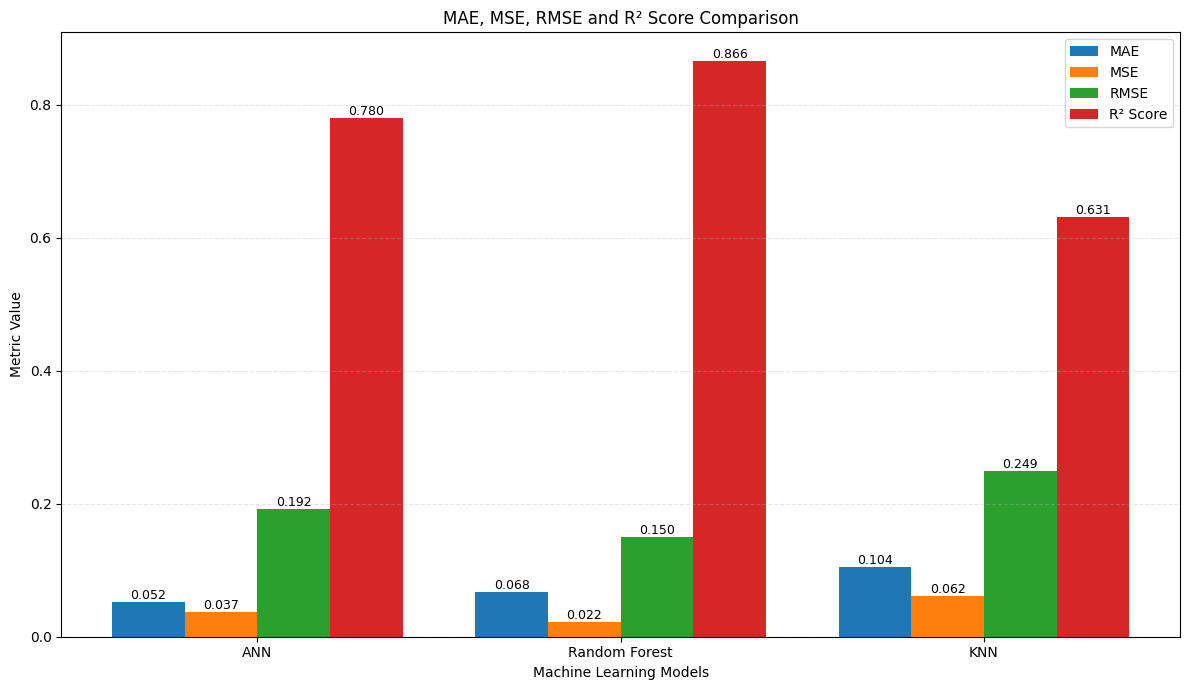

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================
# MODEL NAMES
# ============================================

models = [
    "ANN",
    "Random Forest",
    "KNN"
]


# ============================================
# METRIC VALUES
# ============================================

mae_values = [
    ann_mae,
    rf_mae,
    knn_mae
]

mse_values = [
    ann_mse,
    rf_mse,
    knn_mse
]

rmse_values = [
    ann_rmse,
    rf_rmse,
    knn_rmse
]

r2_values = [
    ann_r2,
    rf_r2,
    knn_r2
]


# ============================================
# BAR PLOT
# ============================================

x = np.arange(len(models))

width = 0.20

plt.figure(figsize=(12, 7))

bar1 = plt.bar(
    x - 1.5 * width,
    mae_values,
    width,
    label="MAE"
)

bar2 = plt.bar(
    x - 0.5 * width,
    mse_values,
    width,
    label="MSE"
)

bar3 = plt.bar(
    x + 0.5 * width,
    rmse_values,
    width,
    label="RMSE"
)

bar4 = plt.bar(
    x + 1.5 * width,
    r2_values,
    width,
    label="R² Score"
)


# ============================================
# LABELS
# ============================================

plt.xlabel("Machine Learning Models")

plt.ylabel("Metric Value")

plt.title(
    "MAE, MSE, RMSE and R² Score Comparison"
)

plt.xticks(
    x,
    models
)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


# ============================================
# VALUE LABELS
# ============================================

def add_values(bars):

    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )


add_values(bar1)
add_values(bar2)
add_values(bar3)
add_values(bar4)


plt.tight_layout()

plt.show()

In [ ]:
import joblib

model_package = {
    "model": rf_model,
    "imputer": imputer,
    "scaler": scaler
}

joblib.dump(
    model_package,
    "stroke_rf_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!
